# Scalars, hourly signals and units

Read SimulationResult as a structured evidence object and reconcile annual and hourly demand.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW, EnergyPlus 24.2.

## Understanding the API in this lesson

`SimulationResult` contains `scalars`, `hourly`, `units`, `time_axis`, `diagnostics` and artifact paths. Scalars summarize a run; hourly arrays preserve timing; units and the validated calendar tell you how those arrays can be interpreted and combined.

The workflow figure ends at comparison because execution alone does not explain an output. Thermal heating, cooling and DHW are distinct from delivery electricity or PV generation. A raw requested engine signal can also use different units from a normalized `_kwh` array, so inspect `result.units` rather than assuming every column is energy.

Reference: [From observed geometry to an accepted energy comparison](../../docs/figures/workflow.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Produce a real result

The runner retains raw requested signals as well as normalized demand arrays. Use the units mapping rather than inferring units from a plot label.

### Read the code and output

The scalar table includes aggregate demands; the units table previews raw and normalized signals. Some raw names contain an engine variable and a zone key. Avoid adding unrelated signal types just because they have equal array lengths. The quantity definition and unit are both part of the interface.

In [2]:
b=building(); result=EnergyPlusRunner(engine()).run(b,OUT/"run")
assert isinstance(result,SimulationResult)
table(result.scalars)
table([{ "signal":key,"unit":unit} for key,unit in result.units.items()][:20])

,field,value
0,space_heating_demand_kwh,66263.28839200501
1,space_heating_demand_eui_kwh_m2,36.812937995558336
2,cooling_demand_kwh,0.0
3,cooling_demand_eui_kwh_m2,0.0
4,dhw_load_kwh,37864.30014025246
5,dhw_load_eui_kwh_m2,21.035722300140257
6,ideal_thermal_load_kwh,104127.58853225748
7,ideal_thermal_load_eui_kwh_m2,57.8486602956986
8,annual_absolute_ground_transfer_kwh,9494.440300882405
9,compile_seconds,0.04786424990743399


,signal,unit
0,Zone People Total Heating Energy::MAIN_MAIN_0,J
1,Zone People Total Heating Energy::MAIN_MAIN_1,J
2,Zone People Total Heating Energy::MAIN_MAIN_2,J
3,Zone Lights Total Heating Energy::MAIN_MAIN_0,J
4,Zone Lights Total Heating Energy::MAIN_MAIN_1,J
5,Zone Lights Total Heating Energy::MAIN_MAIN_2,J
6,Zone Electric Equipment Total Heating Energy::...,J
7,Zone Electric Equipment Total Heating Energy::...,J
8,Zone Electric Equipment Total Heating Energy::...,J
9,Enclosure Windows Total Transmitted Solar Radi...,J


,signal,unit
0,Zone People Total Heating Energy::MAIN_MAIN_0,J
1,Zone People Total Heating Energy::MAIN_MAIN_1,J
2,Zone People Total Heating Energy::MAIN_MAIN_2,J
3,Zone Lights Total Heating Energy::MAIN_MAIN_0,J
4,Zone Lights Total Heating Energy::MAIN_MAIN_1,J
5,Zone Lights Total Heating Energy::MAIN_MAIN_2,J
6,Zone Electric Equipment Total Heating Energy::...,J
7,Zone Electric Equipment Total Heating Energy::...,J
8,Zone Electric Equipment Total Heating Energy::...,J
9,Enclosure Windows Total Transmitted Solar Radi...,J


## Reconcile and plot demand

Annual heating should equal the sum of hourly interval energy. EUI divides energy by the reported conditioned floor area, which changes when basement conditioning changes.

### Read the code and output

Heating EUI is annual heating kWh divided by conditioned floor area in m². The assertions check that hourly, annual and normalized forms agree. Monthly and first-week plots reveal temporal structure that an annual scalar omits; they use the validated result calendar rather than a guessed date index.

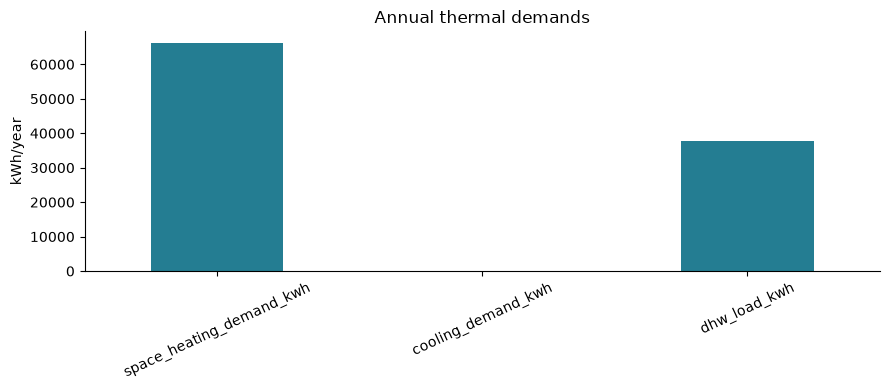

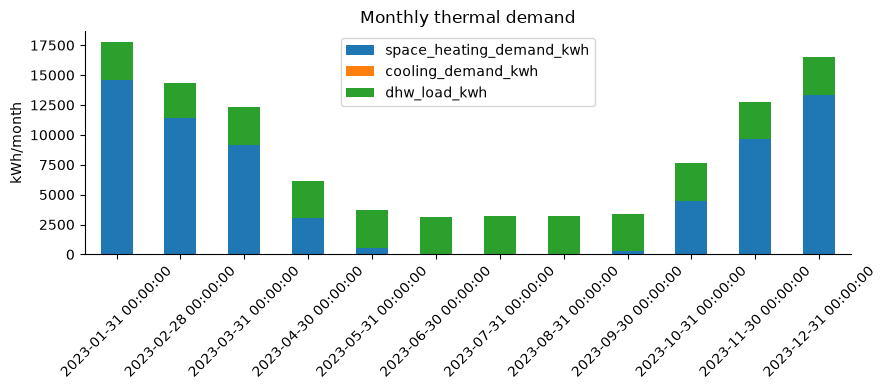

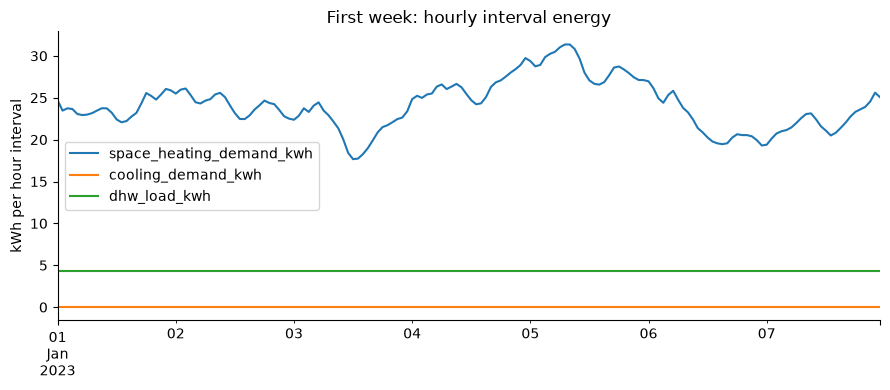

In [3]:
frame=result_plots(result)
for key in ["space_heating_demand_kwh","cooling_demand_kwh","dhw_load_kwh"]:
    assert np.isclose(frame[key].sum(),result.scalars[key])
assert np.isclose(result.scalars["space_heating_demand_eui_kwh_m2"],frame.space_heating_demand_kwh.sum()/b.geometry.conditioned_floor_area_m2)

## Inspect duration and acceptance

Sorted hourly values show demand duration but discard timing. The maximum hourly kWh is numerically an average kW over that hour, not a subhourly design peak.

### Read the code and output

Sorting produces a load-duration curve and discards chronological coincidence. Its maximum is an hourly-average kW because each value covers one hour. Use the original time-indexed series, not the sorted curve, when combining multiple buildings or comparing simultaneous demand and generation.

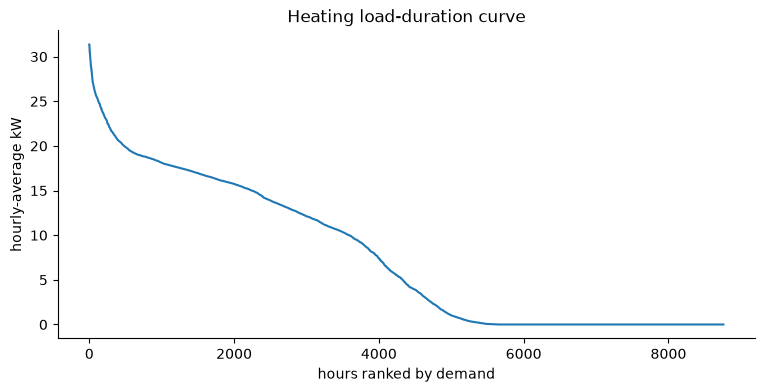

,field,value
0,policy_version,strict-1
1,engine_version,24.2
2,messages,[]
3,accepted,True
4,warning_count,0
5,severe_count,0
6,fatal_count,0
7,invalid_view_factor_count,0
8,err_path,/Users/ssanjay/GitHub/epsm_core/output/demo/09...
9,zoning,"{'effective_mode': 'per_storey', 'on_failure':..."


In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
plt.plot(np.sort(frame.space_heating_demand_kwh.to_numpy())[::-1]); plt.xlabel("hours ranked by demand"); plt.ylabel("hourly-average kW"); plt.title("Heating load-duration curve"); plt.show(); plt.close(fig)
table(result.diagnostics)
assert result.diagnostics["accepted"]

## Interpretation and next experiment

Keep thermal demand, delivered energy and electricity generation distinct. Annual totals alone cannot describe coincident peaks or load-shape diversity.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.